# BoardMind AI - Real-World (IRL) Whiteboard Dataset Evaluation

**Purpose:** Comprehensive end-to-end evaluation of the BoardMind AI pipeline on real-world classroom whiteboard photos (`datasets/irl_whiteboard/`).

### Pipeline Architecture:
1. **Stage 1 (Ultralytics YOLOv8n):** Macro Whiteboard ROI and text region detection.
2. **Stage 2 (RapidOCR ONNX Deep Engine):** High-resolution cropped whiteboard line segmentation and character sequence decoding.
3. **Stage 3 (AI Concept Synthesizer / Local Ollama):** Offline LLM synthesis turning raw transcribed handwriting into structured study notes.


In [1]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
import time

# Ensure project root is in sys.path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import backend.app.detection.whiteboard_detector as wd
import backend.app.recognition.handwriting_recognizer as hr
import backend.app.processing.ai_explainer as ae

importlib.reload(wd)
importlib.reload(hr)
importlib.reload(ae)

from backend.app.detection.whiteboard_detector import get_whiteboard_detector
from backend.app.recognition.handwriting_recognizer import get_handwriting_recognizer
from backend.app.processing.ai_explainer import get_ai_concept_explainer
from backend.app.processing.text_formatter import get_text_formatter

# Initialize services
detector = get_whiteboard_detector(force_reload=True)
recognizer = get_handwriting_recognizer(force_reload=True)
explainer = get_ai_concept_explainer(force_reload=True)
formatter = get_text_formatter()

print("✓ BoardMind AI Services successfully loaded.")
print(f"  • Detector Weights: {detector.model_path.name} ({detector.class_names})")
print(f"  • Recognizer Engine: {recognizer._active_engine_name}")
print(f"  • Ollama Service: {'Available (Host: ' + explainer.ollama_host + ')' if explainer.check_ollama_available() else 'Not running (Fallback to Built-in Synthesizer)'}")


[Detector] Initializing WhiteboardDetector with weights: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\models\whiteboard_detector_best.pt
[Detector] WhiteboardDetector successfully loaded on cpu. Classes: {0: 'Handwritten text', 1: 'Whiteboard'}
[HTR] RapidOCR ONNX Deep Engine initialized successfully on CPU.
✓ BoardMind AI Services successfully loaded.
  • Detector Weights: whiteboard_detector_best.pt ({0: 'Handwritten text', 1: 'Whiteboard'})
  • Recognizer Engine: RapidOCR (ONNX Deep CNN-RNN Engine)
  • Ollama Service: Available (Host: http://127.0.0.1:11434)


## 1. Scan and Catalog the IRL Dataset
Scans `datasets/irl_whiteboard/` recursively for classroom photographs.


In [2]:
irl_dir = PROJECT_ROOT / "datasets" / "irl_whiteboard"
image_extensions = (".jpg", ".jpeg", ".png", ".webp")

# Natural numerical sort (0.jpg, 1.jpg, ..., 23.jpg)
def natural_sort_key(p):
    return (0, int(p.stem)) if p.stem.isdigit() else (1, p.name.lower())

irl_images = sorted([
    p for p in irl_dir.rglob("*") 
    if p.suffix.lower() in image_extensions
], key=natural_sort_key)

print(f"Found {len(irl_images)} real-world classroom images in {irl_dir.relative_to(PROJECT_ROOT)}:\n")
df_catalog = pd.DataFrame([{
    "Filename": img_p.name,
    "Subfolder": str(img_p.parent.relative_to(irl_dir)),
    "Size (KB)": round(img_p.stat().st_size / 1024, 1)
} for img_p in irl_images])

display(df_catalog.head(10))

Found 24 real-world classroom images in datasets\irl_whiteboard:



,Filename,Subfolder,Size (KB)
0,0.jpg,Cleaned_Dataset,4079.6
1,1.jpg,Cleaned_Dataset,2123.1
2,2.jpg,Cleaned_Dataset,2346.6
3,3.jpg,Cleaned_Dataset,4057.3
4,4.jpg,Cleaned_Dataset,2424.8
5,5.jpg,Cleaned_Dataset,3989.4
6,6.jpg,Cleaned_Dataset,3212.0
7,7.jpg,Cleaned_Dataset,3298.9
8,8.jpg,Cleaned_Dataset,3030.2
9,9.jpg,Cleaned_Dataset,2947.0


## 2. Interactive Single-Image Deep Dive
Select an image by **filename** to run the full two-stage vision and AI note generation pipeline with visual bounding box overlays.

Processing: 6.jpg (datasets\irl_whiteboard\Cleaned_Dataset\6.jpg)
Stage 1: Detected 5 region(s):
  [Handwritten text] Conf: 59.6%, Box: [761.2, 1598.7, 2206.2, 1770.7]
  [Handwritten text] Conf: 53.1%, Box: [768.9, 1432.2, 2326.6, 1637.6]
  [Handwritten text] Conf: 48.7%, Box: [713.7, 846.8, 1722.3, 1070.4]
  [Handwritten text] Conf: 44.5%, Box: [744.4, 1259.7, 2364.9, 1495.3]
  [Handwritten text] Conf: 18.4%, Box: [727.1, 1479.0, 1376.3, 1647.9]

✓ Full pipeline finished in 23.01 seconds.
  • Lines Transcribed: 8
  • AI Engine: Local Ollama Edge Engine (llama3.2:3b)


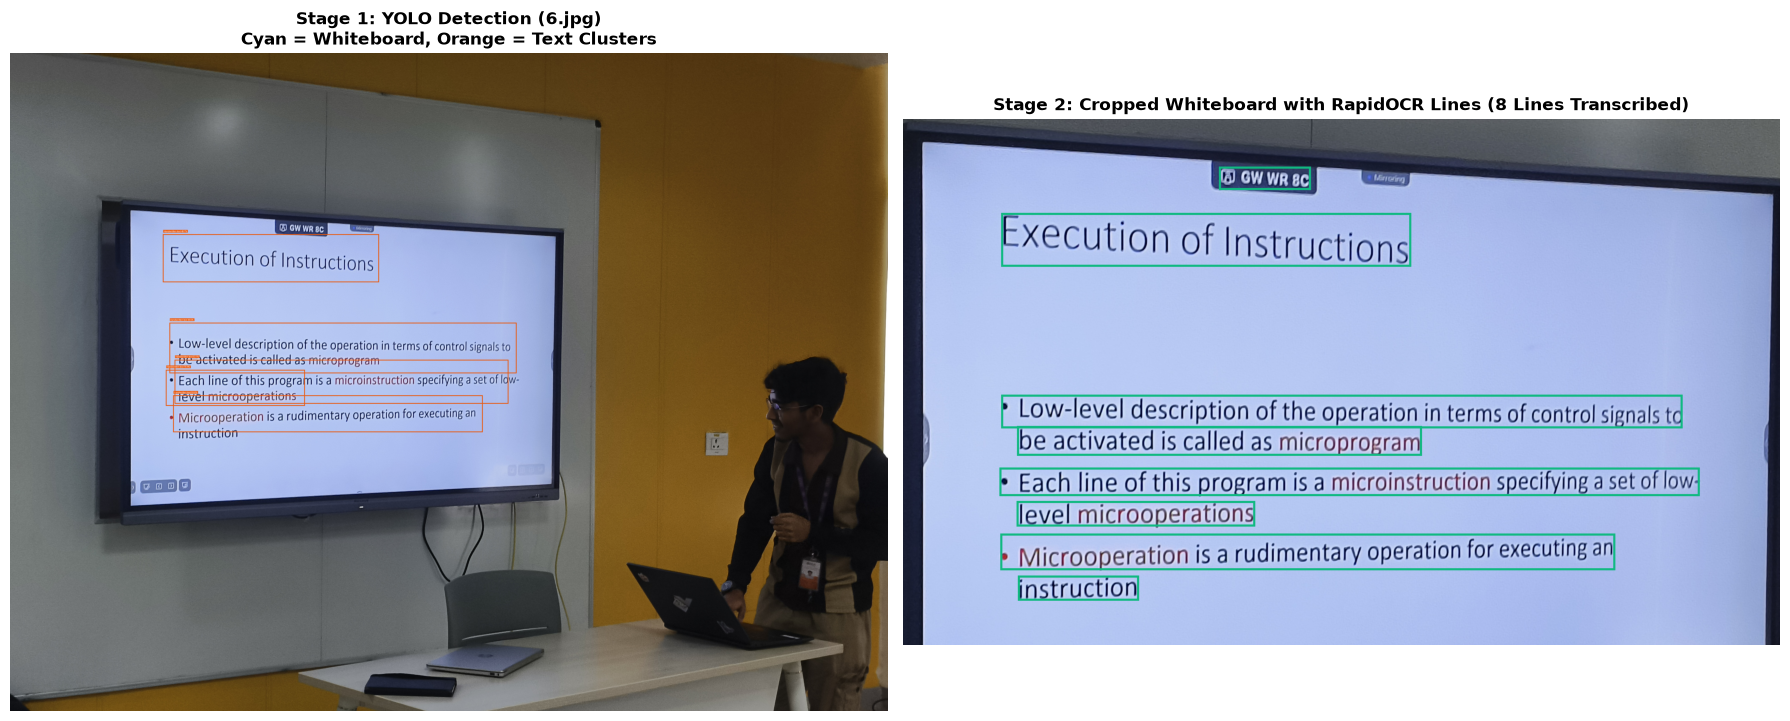

RAW EXTRACTED HANDWRITING LINES:
  [75.3%] GWWR8C
  [89.6%] Execution of Instructions
  [92.5%] : Low - level description of the operation in terms of control signals to
  [89.0%] be activated is called as microprogram
  [91.1%] • Each line of this program is a microinstruction specifying a set of low -
  [87.6%] level microoperations
  [89.8%] • Microoperation is a rudimentary operation for executing an
  [86.2%] instruction

STAGE 3: SYNTHESIZED STUDY NOTES (OLLAMA / ACADEMIC SYNTHESIZER):


# Comprehensive Lecture Title
## 🎯 1. Executive Summary & Core Concept

The lecture notes cover the concept of microprogramming in the context of computer architecture. Microprogramming is a low-level description of the operation in terms of control signals to be activated, providing a detailed, line-by-line specification of the control signals required to execute an instruction.

## 🔍 2. Detailed Technical Breakdown & Definitions

### Microinstruction

A microinstruction is a single line of the microprogram that specifies a set of low-level microoperations. These microoperations are the building blocks of the instruction execution process.

### Microoperation

A microoperation is a rudimentary operation that can be executed to perform a specific function. It is a fundamental component of the microprogramming process.

## 📊 3. Comparative Taxonomy or Key Attributes

| Attribute | Description |
| --- | --- |
| Microinstruction | A single line of the microprogram specifying a set of low-level microoperations. |
| Microoperation | A rudimentary operation that can be executed to perform a specific function. |

## 📐 4. Formal Principles, Workflow or Formulations

The microprogramming process involves the following steps:

1. **Microinstruction Generation**: The microprogram is generated based on the instruction's control signals.
2. **Microoperation Execution**: The microoperations specified in the microinstruction are executed.
3. **Instruction Execution**: The instruction is executed based on the results of the microoperations.

## ⚠️ 5. Important Caveats, Design Pitfalls & Best Practices

*   **Microprogramming Complexity**: The microprogramming process can be complex and time-consuming, requiring careful consideration of instruction-level parallelism and pipelining.
*   **Microinstruction Length**: The length of the microinstruction can impact the overall performance of the system, as longer microinstructions can lead to increased execution time.
*   **Microoperation Optimization**: Optimizing microoperations can significantly impact the performance of the system, as it can reduce the number of cycles required to execute an instruction.

## 📝 6. Actionable Exam Revision Summary

To prepare for an exam on microprogramming, focus on the following key concepts:

*   Microinstructions and microoperations
*   Microprogramming process and workflow
*   Instruction-level parallelism and pipelining
*   Microinstruction length and optimization
*   Microoperation optimization and its impact on system performance

In [6]:
IMAGE_NAME = "6.jpg" 

if isinstance(IMAGE_NAME, int):
    target_path = irl_images[IMAGE_NAME]
else:
    query = str(IMAGE_NAME).strip().lower()
    matches = [
        p for p in irl_images 
        if p.name.lower() == query 
        or p.stem.lower() == query 
        or p.name.lower().startswith(f"{query}.")
    ]
    if not matches:
        available = [p.name for p in irl_images[:10]]
        raise FileNotFoundError(
            f"Image '{IMAGE_NAME}' not found in {irl_dir}.\n"
            f"Available sample filenames: {available}..."
        )
    target_path = matches[0]

print(f"Processing: {target_path.name} ({target_path.relative_to(PROJECT_ROOT)})")

t0 = time.perf_counter()
img_raw = Image.open(target_path)
orig_w, orig_h = img_raw.size

# -------------------------------------------------------------
# STAGE 1: Whiteboard & Text Cluster Detection
# -------------------------------------------------------------
# Dual thresholds: 0.35 for board ROI, 0.15 for handwritten text
detections, primary_box, annotated_stage1 = detector.detect(
    img_raw, 
    conf_board=0.35, 
    conf_text=0.15
)

print(f"Stage 1: Detected {len(detections)} region(s):")
for i, d in enumerate(detections):
    print(f"  [{d.class_name}] Conf: {d.confidence:.1%}, Box: [{d.xmin}, {d.ymin}, {d.xmax}, {d.ymax}]")

# -------------------------------------------------------------
# STAGE 2: Crop Board & Transcribe Handwriting with RapidOCR
# -------------------------------------------------------------
if primary_box:
    cropped_board = img_raw.crop((primary_box.xmin, primary_box.ymin, primary_box.xmax, primary_box.ymax))
else:
    cropped_board = img_raw.copy()

# For very large smartphone images (>1800px), downsample crop slightly for snappy OCR inference
max_dim = 1800
if max(cropped_board.size) > max_dim:
    scale = max_dim / float(max(cropped_board.size))
    ocr_input = cropped_board.resize((int(cropped_board.width * scale), int(cropped_board.height * scale)), Image.Resampling.LANCZOS)
else:
    scale = 1.0
    ocr_input = cropped_board

result = recognizer.recognize(ocr_input)

# Annotate Stage 2 recognized lines on the cropped board
annotated_stage2 = cropped_board.copy()
draw2 = ImageDraw.Draw(annotated_stage2)

for line in result.lines:
    if line.bbox:
        # Scale bbox back to cropped_board dimensions
        xmin, ymin, xmax, ymax = [coord / scale for coord in line.bbox]
        draw2.rectangle([xmin, ymin, xmax, ymax], outline="#10b981", width=max(2, int(cropped_board.width / 400)))

# -------------------------------------------------------------
# STAGE 3: Concept Explanation & Note Synthesis
# -------------------------------------------------------------
ai_explanation = explainer.explain(
    image=cropped_board,
    raw_text=result.raw_text,
    topic_hint=None
)

elapsed = time.perf_counter() - t0
print(f"\n✓ Full pipeline finished in {elapsed:.2f} seconds.")
print(f"  • Lines Transcribed: {len(result.lines)}")
print(f"  • AI Engine: {ai_explanation.get('engine', 'Built-in')}")

# -------------------------------------------------------------
# Side-by-Side Visual Plot
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].imshow(annotated_stage1)
axes[0].set_title(f"Stage 1: YOLO Detection ({target_path.name})\nCyan = Whiteboard, Orange = Text Clusters", fontsize=12, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(annotated_stage2)
axes[1].set_title(f"Stage 2: Cropped Whiteboard with RapidOCR Lines ({len(result.lines)} Lines Transcribed)", fontsize=12, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Display Transcribed Lines
print("=" * 60)
print("RAW EXTRACTED HANDWRITING LINES:")
print("=" * 60)
for l in result.lines:
    print(f"  [{l.confidence:.1%}] {l.text}")

# Display Generated Markdown Notes
from IPython.display import Markdown, display
print("\n" + "=" * 60)
print("STAGE 3: SYNTHESIZED STUDY NOTES (OLLAMA / ACADEMIC SYNTHESIZER):")
print("=" * 60)
display(Markdown(ai_explanation.get("explanation_markdown", "No notes generated.")))


## 3. Automated Batch Processing Across All IRL Images
Processes the entire dataset of real-world photos and compiles metrics into a performance summary table.


In [4]:
batch_records = []
print(f"Executing batch evaluation across all {len(irl_images)} IRL photos...")

for idx, img_path in enumerate(irl_images, 1):
    t_start = time.perf_counter()
    try:
        im = Image.open(img_path)
        dets, p_box, _ = detector.detect(im, conf_board=0.35, conf_text=0.15)
        
        wb_detected = p_box is not None
        wb_conf = p_box.confidence if p_box else 0.0
        text_box_count = sum(1 for d in dets if 'text' in d.class_name.lower())
        
        crop = im.crop((p_box.xmin, p_box.ymin, p_box.xmax, p_box.ymax)) if p_box else im
        
        # Scale down large smartphone images for OCR
        if max(crop.size) > 1800:
            sc = 1800.0 / float(max(crop.size))
            crop_ocr = crop.resize((int(crop.width * sc), int(crop.height * sc)), Image.Resampling.LANCZOS)
        else:
            crop_ocr = crop
            
        ocr_res = recognizer.recognize(crop_ocr)
        mean_ocr_conf = np.mean([l.confidence for l in ocr_res.lines]) if ocr_res.lines else 0.0
        
        duration = time.perf_counter() - t_start
        
        batch_records.append({
            "#": idx,
            "Image": img_path.name,
            "Original Size": f"{im.width}x{im.height}",
            "Whiteboard Detected": "✓ Yes" if wb_detected else "✗ No",
            "Board Conf": f"{wb_conf:.1%}",
            "YOLO Text Blocks": text_box_count,
            "OCR Lines Found": len(ocr_res.lines),
            "Mean OCR Conf": f"{mean_ocr_conf:.1%}",
            "Latency (s)": round(duration, 2)
        })
        print(f"  [{idx:02d}/{len(irl_images)}] {img_path.name}: WB={wb_conf:.1%}, OCR Lines={len(ocr_res.lines)} ({duration:.2f}s)")
    except Exception as e:
        print(f"  [ERROR] {img_path.name}: {e}")

df_results = pd.DataFrame(batch_records)
print("\n=== BATCH EVALUATION COMPLETE ===")
display(df_results)


Executing batch evaluation across all 24 IRL photos...
  [01/24] 0.jpg: WB=47.6%, OCR Lines=13 (10.25s)
  [02/24] 1.jpg: WB=0.0%, OCR Lines=14 (8.69s)
  [03/24] 2.jpg: WB=42.1%, OCR Lines=9 (12.22s)
  [04/24] 3.jpg: WB=35.2%, OCR Lines=10 (11.67s)
  [05/24] 4.jpg: WB=81.1%, OCR Lines=10 (12.47s)
  [06/24] 5.jpg: WB=31.7%, OCR Lines=6 (8.06s)
  [07/24] 6.jpg: WB=44.9%, OCR Lines=8 (10.00s)
  [08/24] 7.jpg: WB=32.4%, OCR Lines=8 (7.09s)
  [09/24] 8.jpg: WB=41.2%, OCR Lines=5 (9.63s)
  [10/24] 9.jpg: WB=25.2%, OCR Lines=10 (12.32s)
  [11/24] 10.jpg: WB=38.9%, OCR Lines=14 (10.66s)
  [12/24] 11.jpg: WB=29.1%, OCR Lines=8 (8.59s)
  [13/24] 12.jpg: WB=0.0%, OCR Lines=5 (7.08s)
  [14/24] 13.jpg: WB=61.0%, OCR Lines=9 (9.26s)
  [15/24] 14.jpg: WB=41.6%, OCR Lines=8 (10.71s)
  [16/24] 15.jpg: WB=30.4%, OCR Lines=7 (10.76s)
  [17/24] 16.jpg: WB=30.9%, OCR Lines=10 (10.33s)
  [18/24] 17.jpg: WB=28.7%, OCR Lines=13 (8.21s)
  [19/24] 18.jpg: WB=24.4%, OCR Lines=19 (12.04s)
  [20/24] 19.jpg: WB=56.5

,#,Image,Original Size,Whiteboard Detected,Board Conf,YOLO Text Blocks,OCR Lines Found,Mean OCR Conf,Latency (s)
0,1,0.jpg,4096x3072,✓ Yes,47.6%,10,13,84.7%,10.25
1,2,1.jpg,4096x3072,✗ No,0.0%,0,14,83.6%,8.69
2,3,2.jpg,4096x3072,✓ Yes,42.1%,19,9,88.9%,12.22
3,4,3.jpg,4096x3072,✓ Yes,35.2%,17,10,87.4%,11.67
4,5,4.jpg,4096x3072,✓ Yes,81.1%,24,10,88.0%,12.47
5,6,5.jpg,4096x3072,✓ Yes,31.7%,4,6,70.1%,8.06
6,7,6.jpg,4096x3072,✓ Yes,44.9%,5,8,87.7%,10.00
7,8,7.jpg,4096x3072,✓ Yes,32.4%,2,8,74.9%,7.09
8,9,8.jpg,4096x3072,✓ Yes,41.2%,2,5,72.9%,9.63
9,10,9.jpg,4096x3072,✓ Yes,25.2%,6,10,74.2%,12.32


## 4. Performance Summary & Report Export
Computes aggregate accuracy and latency statistics and exports the report.


In [5]:
wb_success_count = sum(1 for r in batch_records if r["Whiteboard Detected"] == "✓ Yes")
wb_success_rate = (wb_success_count / len(batch_records)) * 100 if batch_records else 0
avg_lines = np.mean([r["OCR Lines Found"] for r in batch_records]) if batch_records else 0
avg_latency = np.mean([r["Latency (s)"] for r in batch_records]) if batch_records else 0

print("============================================================")
print("IRL WHITEBOARD BENCHMARK SUMMARY")
print("============================================================")
print(f"Total Images Evaluated:       {len(batch_records)}")
print(f"Whiteboard Detection Rate:    {wb_success_rate:.1f}% ({wb_success_count}/{len(batch_records)})")
print(f"Average OCR Lines per Board:  {avg_lines:.1f}")
print(f"Average Latency per Image:    {avg_latency:.2f}s")
print("============================================================")

# Export results
export_dir = PROJECT_ROOT / "runs"
export_dir.mkdir(parents=True, exist_ok=True)
csv_path = export_dir / "irl_whiteboard_evaluation.csv"
df_results.to_csv(csv_path, index=False)
print(f"\n✓ Saved evaluation report to: {csv_path.relative_to(PROJECT_ROOT)}")


IRL WHITEBOARD BENCHMARK SUMMARY
Total Images Evaluated:       24
Whiteboard Detection Rate:    91.7% (22/24)
Average OCR Lines per Board:  9.5
Average Latency per Image:    10.02s

✓ Saved evaluation report to: runs\irl_whiteboard_evaluation.csv
